In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df_VSC = pd.read_csv('vendas_supermercado_com_cliente.csv', sep=',')
df_VSC.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20075 entries, 0 to 20074
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Data         20075 non-null  object 
 1   Produto      20075 non-null  object 
 2   Categoria    20075 non-null  object 
 3   Preço        20075 non-null  float64
 4   Quantidade   20075 non-null  int64  
 5   Desconto     20075 non-null  float64
 6   Total_Venda  20075 non-null  float64
 7   Idade        20075 non-null  int64  
 8   Renda        20075 non-null  float64
dtypes: float64(4), int64(2), object(3)
memory usage: 1.4+ MB


Numa primeira observação, por meio do método info, verificamos a estrutura da tabela, suas colunas e a quantidade de linhas. importante destacar que a tabela não possui dados nulos, o que nos permite trabalhar com todos os dados.

In [3]:
df_VSC.describe()

,Preço,Quantidade,Desconto,Total_Venda,Idade,Renda
count,20075.000000,20075.000000,20075.000000,20075.000000,20075.000000,20075.000000
mean,25.577109,10.007671,0.039760,245.901736,45.992827,2999.034265
std,14.115988,5.488450,0.085011,207.773694,16.482103,1159.717376
min,1.000000,1.000000,0.000000,0.910200,18.000000,1000.380000
25%,13.260000,5.000000,0.000000,75.604500,32.000000,1993.625000
50%,25.660000,10.000000,0.000000,186.320000,46.000000,2998.830000
75%,37.770000,15.000000,0.000000,370.040000,60.000000,4007.675000
max,49.990000,19.000000,0.500000,949.050000,74.000000,4999.760000


Analisando as estatísticas iniciais dos dados numéricos, percebemos, pela distância entre a média e o desvio padrão dos valores para as colunas, há distancia significativa das observações em relação à media. No entando, a relação entre média e mediana demonstra que os dados são pouco afetados por valores extremos.

In [4]:
# verificando duplicidades
df_VSC.duplicated().sum()

np.int64(0)

Não há dados duplicados no data frame.

In [5]:
# convertendo o formato da coluna data:
df_VSC['Data'] = pd.to_datetime(df_VSC['Data'])
df_VSC

,Data,Produto,Categoria,Preço,Quantidade,Desconto,Total_Venda,Idade,Renda
0,2023-01-01,Maçãs,Alimentos Frescos,16.46,10,0.00,164.6000,49,2715.61
1,2023-01-01,Bananas,Alimentos Frescos,2.39,4,0.00,9.5600,29,2280.15
2,2023-01-01,Laranjas,Alimentos Frescos,8.38,5,0.00,41.9000,67,4419.56
3,2023-01-01,Tomates,Alimentos Frescos,2.03,15,0.00,30.4500,29,3809.17
4,2023-01-01,Alface,Alimentos Frescos,37.14,14,0.00,519.9600,24,1013.42
...,...,...,...,...,...,...,...,...,...
20070,2023-12-31,Produtos de higiene para pets,Pet Shop,26.62,15,0.21,315.4470,39,2475.82
20071,2023-12-31,Panelas,Utilidades Domésticas,33.00,19,0.15,532.9500,25,4766.49
20072,2023-12-31,Talheres,Utilidades Domésticas,27.60,12,0.29,235.1520,65,3367.68
20073,2023-12-31,Copos,Utilidades Domésticas,15.35,13,0.25,149.6625,42,3823.50


In [6]:
# Formatando a coluna Data
df_VSCmensal = df_VSC
df_VSCmensal['Data']= df_VSCmensal['Data'].dt.strftime('%m-%Y')
df_VSCmensal

,Data,Produto,Categoria,Preço,Quantidade,Desconto,Total_Venda,Idade,Renda
0,01-2023,Maçãs,Alimentos Frescos,16.46,10,0.00,164.6000,49,2715.61
1,01-2023,Bananas,Alimentos Frescos,2.39,4,0.00,9.5600,29,2280.15
2,01-2023,Laranjas,Alimentos Frescos,8.38,5,0.00,41.9000,67,4419.56
3,01-2023,Tomates,Alimentos Frescos,2.03,15,0.00,30.4500,29,3809.17
4,01-2023,Alface,Alimentos Frescos,37.14,14,0.00,519.9600,24,1013.42
...,...,...,...,...,...,...,...,...,...
20070,12-2023,Produtos de higiene para pets,Pet Shop,26.62,15,0.21,315.4470,39,2475.82
20071,12-2023,Panelas,Utilidades Domésticas,33.00,19,0.15,532.9500,25,4766.49
20072,12-2023,Talheres,Utilidades Domésticas,27.60,12,0.29,235.1520,65,3367.68
20073,12-2023,Copos,Utilidades Domésticas,15.35,13,0.25,149.6625,42,3823.50


--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

# 1. Quais foram as categorias produtos mais vendidos e em quais meses eles tiveram o maior pico de vendas?

In [7]:
vendas_mensal = df_VSCmensal.groupby(['Data','Categoria']).sum()
vendas_mensal

Produto  \
Data    Categoria                                                                        
01-2023 Alimentos Frescos            MaçãsBananasLaranjasTomatesAlfaceCenourasFrang...   
        Bebidas                      RefrigerantesSucosÁgua mineralCervejasVinhosRe...   
        Congelados                   SorvetesPizzas congeladasVegetais congeladosPr...   
        Laticínios e Ovos            LeiteQueijoIogurteManteigaOvosLeiteQueijoIogur...   
        Pet Shop                     Ração para cãesRação para gatosPetiscosBrinque...   
...                                                                                ...   
12-2023 Pet Shop                     Ração para cãesRação para gatosPetiscosBrinque...   
        Produtos de Higiene Pessoal  ShampoosSabonetesCreme dentalDesodorantesPapel...   
        Produtos de Limpeza          DetergentesSabão em póAmaciantesLimpadores mul...   
        Produtos de Mercearia        ArrozFeijãoMacarrãoÓleoAzeiteFarinhaArrozFeijã...   
        Utilidades Domésticas        PanelasTalheresCoposProdutos descartáveis (pra...   

                                        Preço  Quantidade  Desconto  \
Data    Categoria                                                     
01-2023 Alimentos Frescos            11598.21        4595      0.00   
        Bebidas                       4303.28        1651      0.00   
        Congelados                    4081.34        1526      0.00   
        Laticínios e Ovos             4032.13        1609      0.00   
        Pet Shop                      4126.37        1438      0.00   
...                                       ...         ...       ...   
12-2023 Pet Shop                      4223.11        1546     11.86   
        Produtos de Higiene Pessoal   4115.88        1591     11.93   
        Produtos de Limpeza           4122.75        1627     12.11   
        Produtos de Mercearia         4650.25        1950     15.05   
        Utilidades Domésticas         2979.46        1308     10.32   

                                     Total_Venda  Idade       Renda  
Data    Categoria                                                    
01-2023 Alimentos Frescos            116281.5000  21680  1400281.50  
        Bebidas                       47415.7100   7323   444199.10  
        Congelados                    40189.7400   6907   457857.82  
        Laticínios e Ovos             39320.5900   7373   466364.13  
        Pet Shop                      40577.2900   6950   465196.16  
...                                          ...    ...         ...  
12-2023 Pet Shop                      38826.3264   7290   483128.05  
        Produtos de Higiene Pessoal   40137.7948   7081   466023.17  
        Produtos de Limpeza           39277.8173   7036   424848.74  
        Produtos de Mercearia         45589.0551   8401   571701.33  
        Utilidades Domésticas         29239.6143   5833   382651.91  

[108 rows x 7 columns]

## A visualização desse primeiro agrupamento ainda é bastante extensa.

In [8]:
# Vamos agrupar as três principais categorias de cada mês para permitir visualizar todas as linhas.
vendas_mensal_agrupado = vendas_mensal.sort_values(['Data','Total_Venda'], ascending=[True, False]).groupby('Data').head(3)
vendas_mensal_agrupado

Produto  \
Data    Categoria                                                                        
01-2023 Alimentos Frescos            MaçãsBananasLaranjasTomatesAlfaceCenourasFrang...   
        Produtos de Mercearia        ArrozFeijãoMacarrãoÓleoAzeiteFarinhaArrozFeijã...   
        Bebidas                      RefrigerantesSucosÁgua mineralCervejasVinhosRe...   
02-2023 Alimentos Frescos            MaçãsBananasLaranjasTomatesAlfaceCenourasFrang...   
        Produtos de Mercearia        ArrozFeijãoMacarrãoÓleoAzeiteFarinhaArrozFeijã...   
        Pet Shop                     Ração para cãesRação para gatosPetiscosBrinque...   
03-2023 Alimentos Frescos            MaçãsBananasLaranjasTomatesAlfaceCenourasFrang...   
        Produtos de Mercearia        ArrozFeijãoMacarrãoÓleoAzeiteFarinhaArrozFeijã...   
        Laticínios e Ovos            LeiteQueijoIogurteManteigaOvosLeiteQueijoIogur...   
04-2023 Alimentos Frescos            MaçãsBananasLaranjasTomatesAlfaceCenourasFrang...   
        Produtos de Mercearia        ArrozFeijãoMacarrãoÓleoAzeiteFarinhaArrozFeijã...   
        Congelados                   SorvetesPizzas congeladasVegetais congeladosPr...   
05-2023 Alimentos Frescos            MaçãsBananasLaranjasTomatesAlfaceCenourasFrang...   
        Produtos de Mercearia        ArrozFeijãoMacarrãoÓleoAzeiteFarinhaArrozFeijã...   
        Bebidas                      RefrigerantesSucosÁgua mineralCervejasVinhosRe...   
06-2023 Alimentos Frescos            MaçãsBananasLaranjasTomatesAlfaceCenourasFrang...   
        Produtos de Mercearia        ArrozFeijãoMacarrãoÓleoAzeiteFarinhaArrozFeijã...   
        Bebidas                      RefrigerantesSucosÁgua mineralCervejasVinhosRe...   
07-2023 Alimentos Frescos            MaçãsBananasLaranjasTomatesAlfaceCenourasFrang...   
        Bebidas                      RefrigerantesSucosÁgua mineralCervejasVinhosRe...   
        Produtos de Mercearia        ArrozFeijãoMacarrãoÓleoAzeiteFarinhaArrozFeijã...   
08-2023 Alimentos Frescos            MaçãsBananasLaranjasTomatesAlfaceCenourasFrang...   
        Produtos de Mercearia        ArrozFeijãoMacarrãoÓleoAzeiteFarinhaArrozFeijã...   
        Congelados                   SorvetesPizzas congeladasVegetais congeladosPr...   
09-2023 Alimentos Frescos            MaçãsBananasLaranjasTomatesAlfaceCenourasFrang...   
        Produtos de Mercearia        ArrozFeijãoMacarrãoÓleoAzeiteFarinhaArrozFeijã...   
        Laticínios e Ovos            LeiteQueijoIogurteManteigaOvosLeiteQueijoIogur...   
10-2023 Alimentos Frescos            MaçãsBananasLaranjasTomatesAlfaceCenourasFrang...   
        Laticínios e Ovos            LeiteQueijoIogurteManteigaOvosLeiteQueijoIogur...   
        Produtos de Mercearia        ArrozFeijãoMacarrãoÓleoAzeiteFarinhaArrozFeijã...   
11-2023 Alimentos Frescos            MaçãsBananasLaranjasTomatesAlfaceCenourasFrang...   
        Produtos de Mercearia        ArrozFeijãoMacarrãoÓleoAzeiteFarinhaArrozFeijã...   
        Produtos de Higiene Pessoal  ShampoosSabonetesCreme dentalDesodorantesPapel...   
12-2023 Alimentos Frescos            MaçãsBananasLaranjasTomatesAlfaceCenourasFrang...   
        Produtos de Mercearia        ArrozFeijãoMacarrãoÓleoAzeiteFarinhaArrozFeijã...   
        Produtos de Higiene Pessoal  ShampoosSabonetesCreme dentalDesodorantesPapel...   

                                        Preço  Quantidade  Desconto  \
Data    Categoria                                                     
01-2023 Alimentos Frescos            11598.21        4595      0.00   
        Produtos de Mercearia         4943.48        1871      0.00   
        Bebidas                       4303.28        1651      0.00   
02-2023 Alimentos Frescos            10882.42        4199      0.00   
        Produtos de Mercearia         4476.86        1595      0.00   
        Pet Shop                      3680.25        1466      0.00   
03-2023 Alimentos Frescos            12462.31        4832      0.00   
        Produtos de

Text(0.5, 1.0, 'TOTAL DE VENDAS POR MÊS')

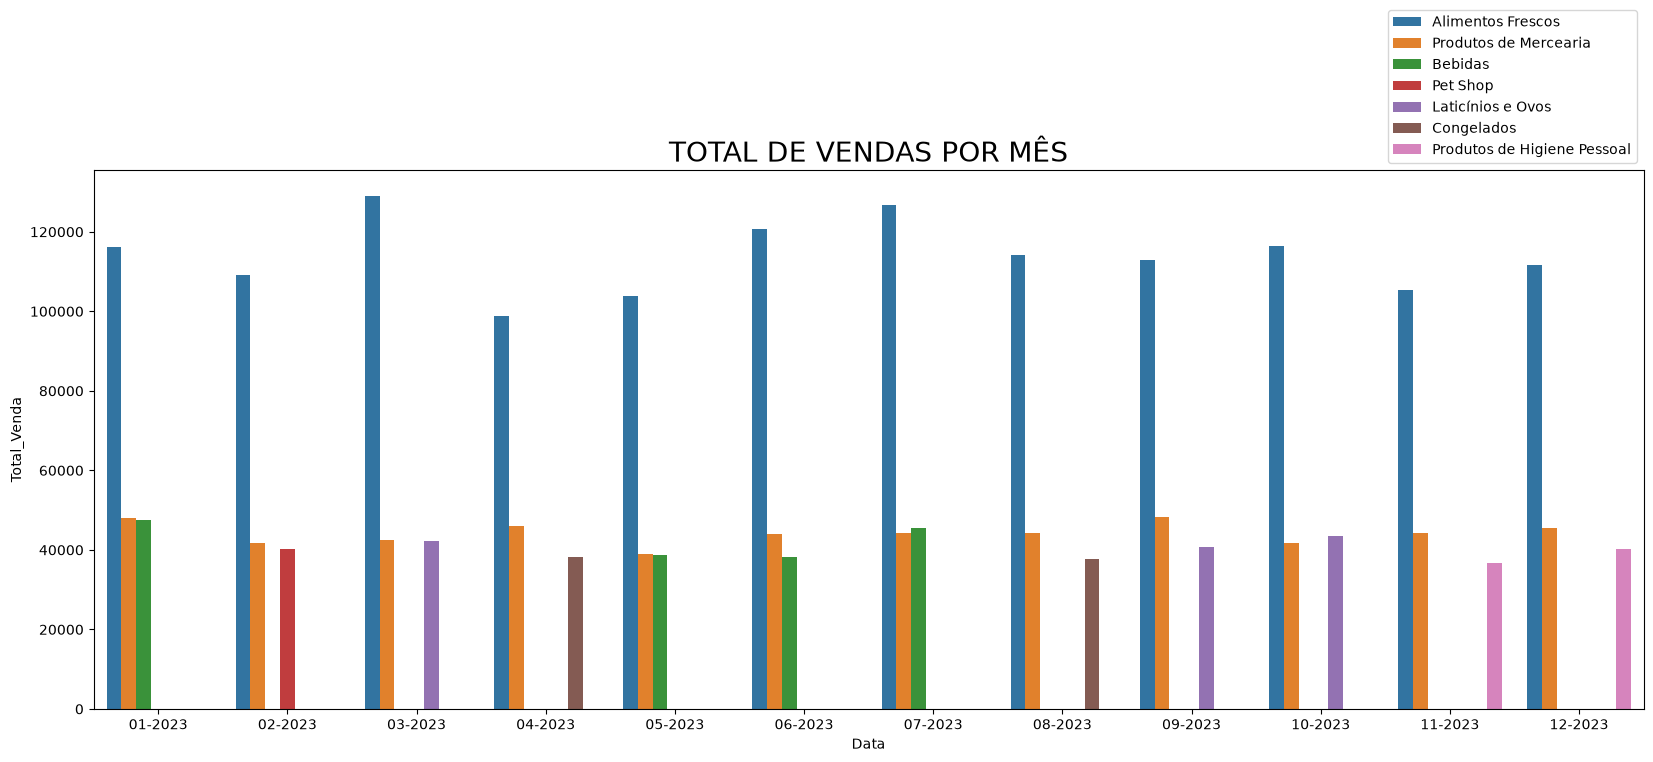

In [37]:
plt.figure(figsize=(20,7))
sns.barplot(vendas_mensal_agrupado, x='Data', y='Total_Venda', hue='Categoria') 
plt.legend(loc='lower right',  bbox_to_anchor=(1, 1))
plt.title('TOTAL DE VENDAS POR MÊS', loc='center',size='20')

## Verifica-se que os ALIMENTOS FRESCOS são sempre os produtos mais vendidos no período, frequentemente acompanhados dos PRODUTOS DE MERCEARIA. No mês de Julho, as BEBIDAS ganham relevância, figurando como a segunda categoria mais vendida. 
## No mês de Outubro, os LATICÍNIOS E OVOS se destacam como a segunda categoria em volume de vendas. 
## Na terceira posição das categorias mais vendidas apareceram ainda, PET SHOP, CONGELADOS e PRODUTOS DE HIGIENE PESSOAL.

## O volume de vendas dos ALIMENTOS FRESCOS OSCILA ENTRE $98.847 e $129.103, com picos de vendas nos meses de Março, Junho e Julho. 
## O volume de vendas dos PRODUTOS DE MERCEARIA varia entre $ 38.992 e $48.079, com picos de vendas em Janeiro, Abril e Setembro.

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

# 2. Qual a média de vendas diárias por categoria de produto?

In [10]:
df_VSC.groupby('Categoria')['Total_Venda'].mean()


Categoria
Alimentos Frescos              249.371590
Bebidas                        248.983103
Congelados                     240.942539
Laticínios e Ovos              252.033135
Pet Shop                       241.277569
Produtos de Higiene Pessoal    241.117524
Produtos de Limpeza            245.230606
Produtos de Mercearia          241.850980
Utilidades Domésticas          246.248340
Name: Total_Venda, dtype: float64

## A média de vendas diárias por categoria varia entre $240,94 e $252,03. A categoria com a maior média diária de vendas é a de LATICÍNIOS E OVOS. 

# 3. Quais   produtos   apresentam   a   maior   sazonalidade   nas   vendas   (ex.:   frutas   e   vegetais, sorvetes)?

In [30]:
# utilizaremos o mesmo método utilizado para a determinação das categorias
vendas_mensal_produto = df_VSCmensal.groupby(['Data','Produto']).sum()
sazonalidade_produto = vendas_mensal_produto.sort_values(['Data','Total_Venda'], ascending=[True, False]).groupby('Data').head(5)
sazonalidade_produto

Categoria  \
Data    Produto                                                                                              
01-2023 Sucos                                            BebidasBebidasBebidasBebidasBebidasBebidasBebi...   
        Tomates                                          Alimentos FrescosAlimentos FrescosAlimentos Fr...   
        Refrigerantes                                    BebidasBebidasBebidasBebidasBebidasBebidasBebi...   
        Vinhos                                           BebidasBebidasBebidasBebidasBebidasBebidasBebi...   
        Alface                                           Alimentos FrescosAlimentos FrescosAlimentos Fr...   
02-2023 Atum                                             Alimentos FrescosAlimentos FrescosAlimentos Fr...   
        Ração para gatos                                 Pet ShopPet ShopPet ShopPet ShopPet ShopPet Sh...   
        Produtos descartáveis (pratos, copos, talheres)  Utilidades DomésticasUtilidades DomésticasUtil...   
        Ração para cães                                  Pet ShopPet ShopPet ShopPet ShopPet ShopPet Sh...   
        Desodorantes                                     Produtos de Higiene PessoalProdutos de Higiene...   
03-2023 Pão integral                                     Alimentos FrescosAlimentos FrescosAlimentos Fr...   
        Esponjas                                         Produtos de LimpezaProdutos de LimpezaProdutos...   
        Detergentes                                      Produtos de LimpezaProdutos de LimpezaProdutos...   
        Cenouras                                         Alimentos FrescosAlimentos FrescosAlimentos Fr...   
        Leite                                            Laticínios e OvosLaticínios e OvosLaticínios e...   
04-2023 Pizzas congeladas                                CongeladosCongeladosCongeladosCongeladosCongel...   
        Água mineral                                     BebidasBebidasBebidasBebidasBebidasBebidasBebi...   
        Farinha                                          Produtos de MerceariaProdutos de MerceariaProd...   
        Atum                                             Alimentos FrescosAlimentos FrescosAlimentos Fr...   
        Sabão em pó                                      Produtos de LimpezaProdutos de LimpezaProdutos...   
05-2023 Refrigerantes                                    BebidasBebidasBebidasBebidasBebidasBebidasBebi...   
        Talheres                                         Utilidades DomésticasUtilidades DomésticasUtil...   
        Vinhos                                           BebidasBebidasBebidasBebidasBebidasBebidasBebi...   
        Salmão                                           Alimentos FrescosAlimentos FrescosAlimentos Fr...   
        Macarrão                                         Produtos de MerceariaProdutos de MerceariaProd...   
06-2023 Maçãs                                            Alimentos FrescosAlimentos FrescosAlimentos Fr...   
        Produtos descartáveis (pratos, copos, talheres)  Utilidades DomésticasUtilidades DomésticasUtil...   
        Cervejas                                         BebidasBebidasBebidasBebidasBebidasBebidasBebi...   
        Manteiga                                         Laticínios e OvosLaticínios e OvosLaticínios e...   
        Tomates                                          Alimentos FrescosAlimentos FrescosAlimentos Fr...   
07-2023 Alface                                           Alimentos FrescosAlimentos FrescosAlimentos Fr...   
        Creme dental                                     Produtos de Higiene PessoalProdutos de Higiene...   
        Detergentes                                      Produtos de LimpezaProdutos de LimpezaProdutos...   
        Panelas                                          Utilidades DomésticasUtilidades DomésticasUtil...   
        Vinhos                                           BebidasBebidasBebidasBebidasBebidasBebidasBebi...   
08-2023 Croissants         

## A distribuição de vendas de produtos por mês demonstra ausência de regularidade no domínio por produto ao longo de um ano. Talvez seja necessário comparar vários anos para identificar algum padrão.

# 4.Quais as faixas etárias contribuíram mais para as vendas totais? Para responder essa pergunta, crie uma coluna com a faixa etária, considerando: entre 18 e 35 (jovem), entre 36 e 59 (adulto) e acima de 60 anos (idoso)

In [ ]:
# Criando a coluna de faixa etária e verificando nulos na mesma coluna coluna
df_VSC['Faixa_Etaria'] = ''
for i in range(len(df_VSC)):
    idade = df_VSC.loc[i, 'Idade']
    if idade <= 35:
        df_VSC.loc[i, 'Faixa_Etaria'] = 'Jovem'
    elif idade <= 59:
        df_VSC.loc[i, 'Faixa_Etaria'] = 'Adulto'
    else:
        df_VSC.loc[i, 'Faixa_Etaria'] = 'Idoso'

df_VSC.info()
    

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20075 entries, 0 to 20074
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Data          20075 non-null  object 
 1   Produto       20075 non-null  object 
 2   Categoria     20075 non-null  object 
 3   Preço         20075 non-null  float64
 4   Quantidade    20075 non-null  int64  
 5   Desconto      20075 non-null  float64
 6   Total_Venda   20075 non-null  float64
 7   Idade         20075 non-null  int64  
 8   Renda         20075 non-null  float64
 9   Faixa_Etaria  20075 non-null  object 
dtypes: float64(4), int64(2), object(4)
memory usage: 1.5+ MB


In [27]:
vendas_idade = df_VSC.groupby('Faixa_Etaria')['Total_Venda'].sum()
vendas_idade.sort_values(ascending=False)

Faixa_Etaria
Adulto    2.102042e+06
Jovem     1.537183e+06
Idoso     1.297252e+06
Name: Total_Venda, dtype: float64

C:\Users\lamar\AppData\Local\Temp\ipykernel_13368\3030073297.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(df_VSC, x='Faixa_Etaria', palette="Set1")


Text(0.5, 1.0, 'TOTAL DE VENDAS POR IDADE')

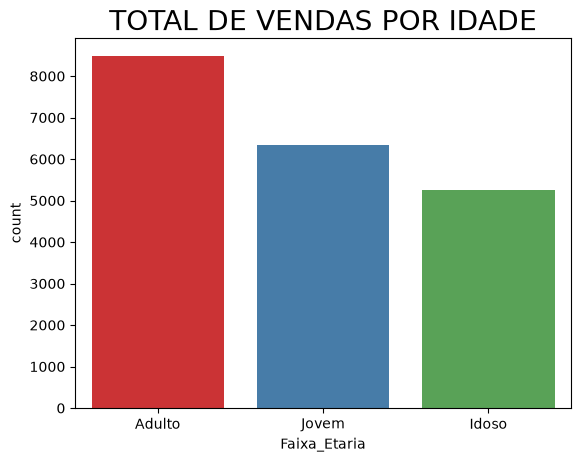

In [46]:
sns.countplot(df_VSC, x='Faixa_Etaria', palette="Set1")
plt.title('TOTAL DE VENDAS POR IDADE', loc='center',size='20')

## Identificamos que a faixa etária dos adultos contribuiu com o maior volume de vendas no ano de 2023, seguido pela faixa etária dos jovens e depois dos idosos.